# Análise de importância das variáveis: Random Forest e XGBoost

Devido à quantidade de características presentes no dataset, será realizada uma análise utilizando os algoritmos **Random Forest** e **XGBoost**, com o objetivo de identificar quais variáveis apresentam maior importância para a predição do resultado das partidas.

Inicialmente, será treinado e avaliado um modelo Random Forest. Em seguida, o mesmo processo será realizado utilizando XGBoost. Os resultados serão comparados para verificar o desempenho preditivo de cada algoritmo e identificar as características consideradas mais importantes por cada modelo.

Essa análise permitirá compreender quais variáveis possuem maior relevância para a classificação do vencedor e poderá auxiliar na seleção de características para as próximas etapas do trabalho.

In [4]:
%pip install pandas openpyxl scikit-learn matplotlib seaborn xgboost

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   --------------------------------- ------ 9.2/10.9 MB 45.6 MB/s eta 0:00:01
   ---------------------------------------  10.7/10.9 MB 48.0 MB/s eta 0:00:01
   ---------------------------------------  10.7/10.9 MB 48.0 MB/s eta 0:00:01
   ---------------------------------------  10.7/10.9 MB 48.0 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 11.5 MB/s  0:00:00
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -------------------------------------- - 8.1/8.4 MB 50.8 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 50.8 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 50.8 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 10.5 MB/s  0:00:00
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------  9.4/9.5 MB 61.9 MB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd

# Configuração para reprodutibilidade
SEED = 42

# Carregamento do dataset
DATASET_PATH = "../data/team-time-series-10000.xlsx"

df = pd.read_excel(DATASET_PATH)

print(f"Seed definida: {SEED}")
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas")

display(df.head())

Seed definida: 42
Dimensões do dataset: 289264 linhas e 108 colunas


,match_id,timestep,vencedor,blue_championStats.abilityHaste,blue_championStats.abilityPower,blue_championStats.armor,blue_championStats.attackDamage,blue_championStats.health,blue_currentGold,blue_damageStats.magicDamageDone,...,diff_kills,diff_deaths,diff_assists,diff_dragons,diff_elder_dragons,diff_barons,diff_rift_heralds,diff_atakhan,diff_towers_destroyed,diff_inhibitors_destroyed
0,BR1_3258230874,0,200,0,0,151,278,3080,2100,0,...,0,0,0,0,0,0,0,0,0,0
1,BR1_3258230874,1,200,0,9,151,318,3559,0,15,...,0,0,0,0,0,0,0,0,0,0
2,BR1_3258230874,2,200,0,9,166,329,3135,1846,304,...,1,-1,1,0,0,0,0,0,0,0
3,BR1_3258230874,3,200,0,9,190,375,3290,1776,1777,...,1,-1,1,0,0,0,0,0,0,0
4,BR1_3258230874,4,200,0,9,217,388,3159,3219,3237,...,1,-1,1,0,0,0,0,0,0,0


In [7]:
# Seleciona somente os timesteps de 0 a 20
df_experimento = df[df["timestep"].between(0, 20)].copy()

# Verifica a quantidade de registros por partida
registros_por_partida = df_experimento.groupby("match_id").size()

# Verifica se todas as partidas possuem exatamente 21 registros
partidas_validas = (registros_por_partida == 21).sum()

print("=" * 50)
print("       SELEÇÃO DOS PRIMEIROS 20 MINUTOS")
print("=" * 50)

print(f"\nTotal de registros: {len(df_experimento)}")
print(f"Total de partidas: {df_experimento['match_id'].nunique()}")
print(f"Partidas com 21 registros: {partidas_validas}")
print(f"Partidas com quantidade diferente de 21 registros: {len(registros_por_partida) - partidas_validas}")

       SELEÇÃO DOS PRIMEIROS 20 MINUTOS

Total de registros: 210000
Total de partidas: 10000
Partidas com 21 registros: 10000
Partidas com quantidade diferente de 21 registros: 0


In [8]:
# Identifica as características utilizadas pelo modelo
feature_columns = [
    col for col in df_experimento.columns
    if col not in ["match_id", "timestep", "vencedor"]
]

# Ordena os registros temporalmente dentro de cada partida
df_ordenado = df_experimento.sort_values(
    ["match_id", "timestep"]
)

# Transforma cada partida em uma única linha
X = df_ordenado.pivot(
    index="match_id",
    columns="timestep",
    values=feature_columns
)

# Organiza as colunas para manter a ordem temporal
X = X.reindex(
    columns=pd.MultiIndex.from_product(
        [feature_columns, range(21)]
    )
)

# Transforma os nomes das colunas em identificadores únicos
X.columns = [
    f"{feature}_t{timestep}"
    for feature, timestep in X.columns
]

# Obtém o vencedor de cada partida
y = (
    df_ordenado
    .drop_duplicates(subset="match_id")
    .set_index("match_id")["vencedor"]
)

# Garante que X e y estejam na mesma ordem
y = y.loc[X.index]

print("=" * 50)
print("       TRANSFORMAÇÃO DAS PARTIDAS")
print("=" * 50)

print(f"\nFormato de X: {X.shape}")
print(f"Formato de y: {y.shape}")
print(f"Características por partida: {X.shape[1]}")
print(f"Total de partidas: {X.shape[0]}")

display(X.head())

       TRANSFORMAÇÃO DAS PARTIDAS

Formato de X: (10000, 2205)
Formato de y: (10000,)
Características por partida: 2205
Total de partidas: 10000


,blue_championStats.abilityHaste_t0,blue_championStats.abilityHaste_t1,blue_championStats.abilityHaste_t2,blue_championStats.abilityHaste_t3,blue_championStats.abilityHaste_t4,blue_championStats.abilityHaste_t5,blue_championStats.abilityHaste_t6,blue_championStats.abilityHaste_t7,blue_championStats.abilityHaste_t8,blue_championStats.abilityHaste_t9,...,diff_inhibitors_destroyed_t11,diff_inhibitors_destroyed_t12,diff_inhibitors_destroyed_t13,diff_inhibitors_destroyed_t14,diff_inhibitors_destroyed_t15,diff_inhibitors_destroyed_t16,diff_inhibitors_destroyed_t17,diff_inhibitors_destroyed_t18,diff_inhibitors_destroyed_t19,diff_inhibitors_destroyed_t20
match_id,,,,,,,,,,,,,,,,,,,,,
BR1_3258230874,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BR1_3258239797,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BR1_3258250415,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BR1_3258578050,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BR1_3258588180,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
# Define os índices de separação
total_partidas = len(X)

indice_treino = int(total_partidas * 0.70)
indice_validacao = int(total_partidas * 0.85)

# Divide os dados respeitando a ordem cronológica
X_train = X.iloc[:indice_treino]
y_train = y.iloc[:indice_treino]

X_val = X.iloc[indice_treino:indice_validacao]
y_val = y.iloc[indice_treino:indice_validacao]

X_test = X.iloc[indice_validacao:]
y_test = y.iloc[indice_validacao:]

print("=" * 50)
print("          DIVISÃO DOS DADOS")
print("=" * 50)

print(f"\nTreinamento: {len(X_train)} partidas ({len(X_train)/total_partidas*100:.1f}%)")
print(f"Validação:   {len(X_val)} partidas ({len(X_val)/total_partidas*100:.1f}%)")
print(f"Teste:       {len(X_test)} partidas ({len(X_test)/total_partidas*100:.1f}%)")

print("\nIntervalos dos conjuntos:")
print(f"Treinamento: {X_train.index[0]} até {X_train.index[-1]}")
print(f"Validação:   {X_val.index[0]} até {X_val.index[-1]}")
print(f"Teste:       {X_test.index[0]} até {X_test.index[-1]}")

          DIVISÃO DOS DADOS

Treinamento: 7000 partidas (70.0%)
Validação:   1500 partidas (15.0%)
Teste:       1500 partidas (15.0%)

Intervalos dos conjuntos:
Treinamento: BR1_3258230874 até BR1_3290517066
Validação:   BR1_3290520390 até BR1_3293314375
Teste:       BR1_3293315809 até BR1_3296672944


In [10]:
from sklearn.ensemble import RandomForestClassifier

# Criação do modelo
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_features="sqrt",
    random_state=SEED,
    n_jobs=-1
)

# Treinamento
print("Iniciando treinamento do Random Forest...")

random_forest.fit(X_train, y_train)

print("Treinamento concluído!")

Iniciando treinamento do Random Forest...
Treinamento concluído!


In [11]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# Previsões
y_val_pred = random_forest.predict(X_val)
y_test_pred = random_forest.predict(X_test)

# Avaliação na validação
val_accuracy = accuracy_score(y_val, y_val_pred)
val_f1 = f1_score(y_val, y_val_pred, average="macro")
val_balanced_acc = balanced_accuracy_score(y_val, y_val_pred)

# Avaliação no teste
test_accuracy = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average="macro")
test_balanced_acc = balanced_accuracy_score(y_test, y_test_pred)

print("=" * 55)
print("             AVALIAÇÃO - RANDOM FOREST")
print("=" * 55)

print("\nConjunto de validação:")
print(f"  Accuracy:          {val_accuracy:.4f}")
print(f"  F1-score (Macro):  {val_f1:.4f}")
print(f"  Balanced Accuracy:{val_balanced_acc:.4f}")

print("\nConjunto de teste:")
print(f"  Accuracy:          {test_accuracy:.4f}")
print(f"  F1-score (Macro):  {test_f1:.4f}")
print(f"  Balanced Accuracy:{test_balanced_acc:.4f}")

             AVALIAÇÃO - RANDOM FOREST

Conjunto de validação:
  Accuracy:          0.7753
  F1-score (Macro):  0.7726
  Balanced Accuracy:0.7718

Conjunto de teste:
  Accuracy:          0.7507
  F1-score (Macro):  0.7493
  Balanced Accuracy:0.7492


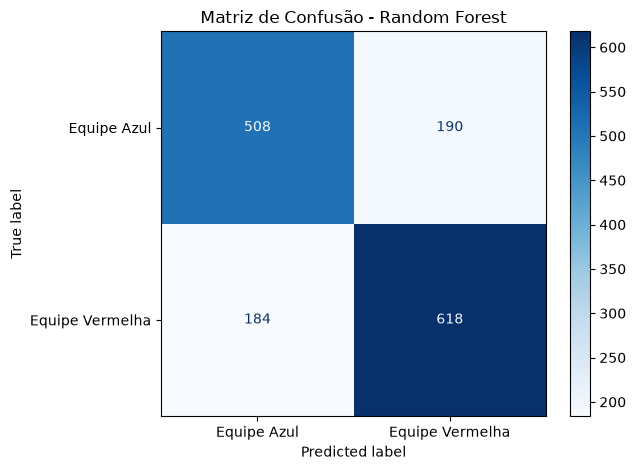

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcula a matriz de confusão do conjunto de teste
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[100, 200]
)

# Configura a visualização
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Equipe Azul", "Equipe Vermelha"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Matriz de Confusão - Random Forest")
plt.tight_layout()
plt.show()

In [13]:
# Obtém a importância de cada característica
importancias = pd.DataFrame({
    "variavel_timestep": X_train.columns,
    "importancia": random_forest.feature_importances_
})

# Recupera o nome da variável original, removendo o sufixo do timestep
importancias["variavel"] = importancias["variavel_timestep"].str.rsplit("_t", n=1).str[0]

# Soma as importâncias dos 21 timesteps de cada variável
importancias_agrupadas = (
    importancias
    .groupby("variavel")["importancia"]
    .sum()
    .sort_values(ascending=False)
)

# Seleciona as 20 variáveis mais importantes
top_20 = importancias_agrupadas.head(20)

print("=" * 55)
print("       20 VARIÁVEIS MAIS IMPORTANTES - RANDOM FOREST")
print("=" * 55)

for posicao, (variavel, importancia) in enumerate(top_20.items(), start=1):
    print(f"{posicao:2d}. {variavel:<50} {importancia:.6f}")

       20 VARIÁVEIS MAIS IMPORTANTES - RANDOM FOREST
 1. diff_totalGold                                     0.072978
 2. diff_xp                                            0.051311
 3. diff_level                                         0.040716
 4. diff_damageStats.totalDamageDone                   0.030613
 5. diff_deaths                                        0.028828
 6. diff_kills                                         0.024265
 7. red_xp                                             0.023983
 8. blue_totalGold                                     0.021751
 9. red_totalGold                                      0.020844
10. diff_towers_destroyed                              0.020573
11. blue_xp                                            0.017998
12. diff_championStats.health                          0.015026
13. red_damageStats.totalDamageDone                    0.014814
14. red_level                                          0.014517
15. diff_currentGold                               

# Análise com XGBoost
Após realizar o treinamento e a avaliação utilizando Random Forest, será utilizado o algoritmo XGBoost para realizar a mesma tarefa de classificação. Os resultados serão comparados para avaliar o desempenho dos modelos e identificar as variáveis mais importantes para a predição do vencedor das partidas.

In [26]:
from xgboost import XGBClassifier

# Codificação dos vencedores: 100 -> 0 e 200 -> 1
y_train_xgb = y_train.map({100: 0, 200: 1})

print("Rótulos preparados para o XGBoost!")
print("\nDistribuição das classes:")
print(y_train_xgb.value_counts().sort_index())

Rótulos preparados para o XGBoost!

Distribuição das classes:
vencedor
0    3223
1    3777
Name: count, dtype: int64


In [27]:
# Criação do modelo XGBoost
xgboost_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=-1,
    tree_method="hist"
)

print("Modelo XGBoost configurado!")

Modelo XGBoost configurado!


In [28]:
import time

# Treinamento do modelo
print("Iniciando treinamento do XGBoost...")

inicio = time.time()

xgboost_model.fit(X_train, y_train_xgb)

tempo_treinamento = time.time() - inicio

print("Treinamento concluído!")
print(f"Tempo de treinamento: {tempo_treinamento:.1f}s")

Iniciando treinamento do XGBoost...
Treinamento concluído!
Tempo de treinamento: 30.4s


In [29]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# Codificação dos vencedores nos conjuntos de validação e teste
y_val_xgb = y_val.map({100: 0, 200: 1})
y_test_xgb = y_test.map({100: 0, 200: 1})

# Previsões
y_val_pred_xgb = xgboost_model.predict(X_val)
y_test_pred_xgb = xgboost_model.predict(X_test)

# Avaliação na validação
val_accuracy_xgb = accuracy_score(y_val_xgb, y_val_pred_xgb)
val_f1_xgb = f1_score(y_val_xgb, y_val_pred_xgb, average="macro")
val_balanced_acc_xgb = balanced_accuracy_score(y_val_xgb, y_val_pred_xgb)

# Avaliação no teste
test_accuracy_xgb = accuracy_score(y_test_xgb, y_test_pred_xgb)
test_f1_xgb = f1_score(y_test_xgb, y_test_pred_xgb, average="macro")
test_balanced_acc_xgb = balanced_accuracy_score(y_test_xgb, y_test_pred_xgb)

print("=" * 55)
print("             AVALIAÇÃO - XGBOOST")
print("=" * 55)

print("\nConjunto de validação:")
print(f"  Accuracy:          {val_accuracy_xgb:.4f}")
print(f"  F1-score (Macro):  {val_f1_xgb:.4f}")
print(f"  Balanced Accuracy: {val_balanced_acc_xgb:.4f}")

print("\nConjunto de teste:")
print(f"  Accuracy:          {test_accuracy_xgb:.4f}")
print(f"  F1-score (Macro):  {test_f1_xgb:.4f}")
print(f"  Balanced Accuracy: {test_balanced_acc_xgb:.4f}")

             AVALIAÇÃO - XGBOOST

Conjunto de validação:
  Accuracy:          0.7693
  F1-score (Macro):  0.7665
  Balanced Accuracy: 0.7657

Conjunto de teste:
  Accuracy:          0.7547
  F1-score (Macro):  0.7529
  Balanced Accuracy: 0.7525


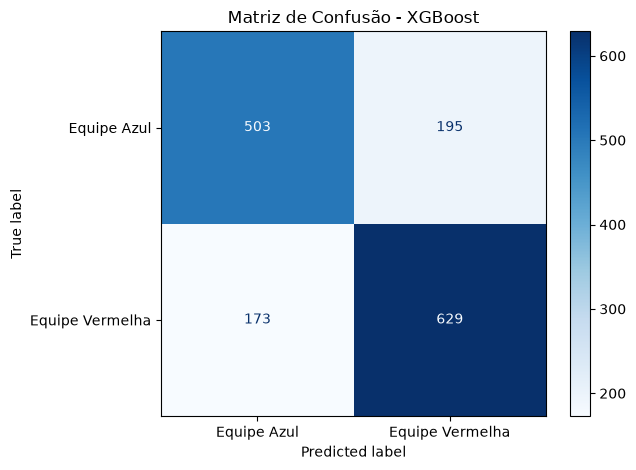

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calcula a matriz de confusão do conjunto de teste
cm_xgb = confusion_matrix(
    y_test_xgb,
    y_test_pred_xgb,
    labels=[0, 1]
)

# Configura a visualização
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Equipe Azul", "Equipe Vermelha"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Matriz de Confusão - XGBoost")
plt.tight_layout()
plt.show()

In [31]:
# Obtém a importância de cada característica
importancias_xgb = pd.DataFrame({
    "variavel_timestep": X_train.columns,
    "importancia": xgboost_model.feature_importances_
})

# Recupera o nome da variável original, removendo o sufixo do timestep
importancias_xgb["variavel"] = (
    importancias_xgb["variavel_timestep"]
    .str.rsplit("_t", n=1)
    .str[0]
)

# Soma as importâncias dos 21 timesteps de cada variável
importancias_agrupadas_xgb = (
    importancias_xgb
    .groupby("variavel")["importancia"]
    .sum()
    .sort_values(ascending=False)
)

# Seleciona as 20 variáveis mais importantes
top_20_xgb = importancias_agrupadas_xgb.head(20)

print("=" * 55)
print("       20 VARIÁVEIS MAIS IMPORTANTES - XGBOOST")
print("=" * 55)

for posicao, (variavel, importancia) in enumerate(top_20_xgb.items(), start=1):
    print(f"{posicao:2d}. {variavel:<50} {importancia:.6f}")

       20 VARIÁVEIS MAIS IMPORTANTES - XGBOOST
 1. diff_totalGold                                     0.026333
 2. diff_xp                                            0.020080
 3. red_championStats.attackDamage                     0.018126
 4. diff_level                                         0.016447
 5. diff_dragons                                       0.016113
 6. diff_damageStats.trueDamageTaken                   0.015606
 7. red_damageStats.physicalDamageTaken                0.015354
 8. diff_championStats.attackDamage                    0.015301
 9. blue_damageStats.trueDamageDone                    0.015209
10. blue_damageStats.totalDamageDoneToChampions        0.015165
11. blue_championStats.abilityPower                    0.015046
12. diff_damageStats.magicDamageDone                   0.014739
13. diff_damageStats.trueDamageDoneToChampions         0.014710
14. red_damageStats.physicalDamageDoneToChampions      0.014342
15. blue_championStats.attackDamage                    0.

### Comparação dos modelos e seleção de variáveis

Após o treinamento e a avaliação dos modelos Random Forest e XGBoost, será realizada uma comparação dos resultados obtidos com o baseline ingênuo, utilizando as métricas de avaliação Accuracy, F1-score (Macro) e Balanced Accuracy.

Em seguida, será realizada uma análise das variáveis consideradas mais importantes por ambos os algoritmos. A partir da intersecção dos rankings de importância, serão identificadas as **cinco variáveis mais importantes em comum** entre os modelos. Caso necessário, o limite inicial de 20 variáveis será ampliado igualmente para os dois rankings, até que seja possível identificar pelo menos cinco variáveis compartilhadas.

Essas cinco variáveis serão selecionadas para um novo experimento, no qual será avaliado o desempenho dos classificadores utilizando um conjunto reduzido de características. O objetivo é investigar se a redução da dimensionalidade mantém ou melhora a capacidade preditiva dos modelos.

COMPARAÇÃO DOS MODELOS - CONJUNTO DE TESTE


,Baseline Ingênuo,Random Forest,XGBoost
Accuracy,0.5347,0.7507,0.7547
F1-score (Macro),0.3484,0.7493,0.7529
Balanced Accuracy,0.5000,0.7492,0.7525


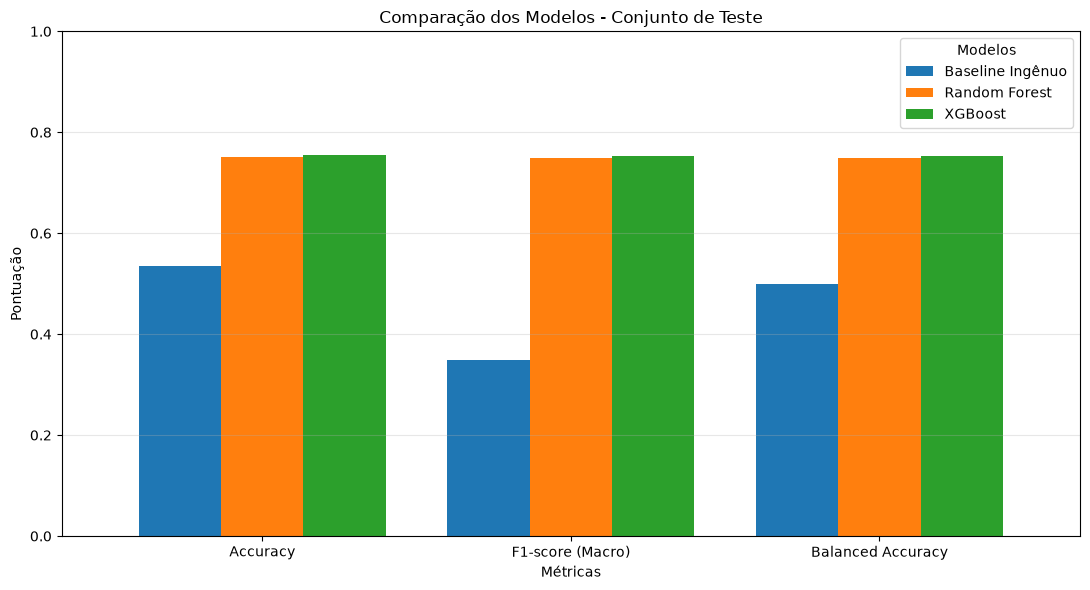

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Métricas do Baseline Ingênuo
baseline_accuracy = 0.5347
baseline_f1 = 0.3484
baseline_balanced_acc = 0.5000

# Organiza os resultados dos três modelos
resultados = pd.DataFrame({
    "Baseline Ingênuo": [
        baseline_accuracy,
        baseline_f1,
        baseline_balanced_acc
    ],
    "Random Forest": [
        test_accuracy,
        test_f1,
        test_balanced_acc
    ],
    "XGBoost": [
        test_accuracy_xgb,
        test_f1_xgb,
        test_balanced_acc_xgb
    ]
}, index=[
    "Accuracy",
    "F1-score (Macro)",
    "Balanced Accuracy"
])

print("COMPARAÇÃO DOS MODELOS - CONJUNTO DE TESTE")
display(resultados.round(4))

# Gráfico de barras agrupadas
ax = resultados.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Comparação dos Modelos - Conjunto de Teste")
plt.ylabel("Pontuação")
plt.xlabel("Métricas")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Modelos")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
# Define a quantidade inicial de variáveis em cada ranking
limite_top = 20

# Amplia igualmente os rankings até encontrar pelo menos
# cinco variáveis em comum
while limite_top <= len(importancias_agrupadas):

    top_rf = importancias_agrupadas.head(limite_top)
    top_xgb = importancias_agrupadas_xgb.head(limite_top)

    variaveis_comuns = set(top_rf.index).intersection(
        set(top_xgb.index)
    )

    if len(variaveis_comuns) >= 5:
        break

    limite_top += 1

# Calcula a posição de cada variável nos dois rankings
ranking_rf = importancias_agrupadas.rank(
    ascending=False,
    method="min"
)

ranking_xgb = importancias_agrupadas_xgb.rank(
    ascending=False,
    method="min"
)

# Organiza as variáveis compartilhadas
resultado_intersecao = pd.DataFrame({
    "Importância RF": importancias_agrupadas.loc[
        list(variaveis_comuns)
    ],
    "Ranking RF": ranking_rf.loc[list(variaveis_comuns)],
    "Importância XGBoost": importancias_agrupadas_xgb.loc[
        list(variaveis_comuns)
    ],
    "Ranking XGBoost": ranking_xgb.loc[list(variaveis_comuns)]
})

# Calcula a posição média nos dois rankings
resultado_intersecao["Ranking médio"] = (
    resultado_intersecao["Ranking RF"] +
    resultado_intersecao["Ranking XGBoost"]
) / 2

# Seleciona as cinco variáveis com melhor posição média
resultado_intersecao = resultado_intersecao.sort_values(
    "Ranking médio"
)

cinco_variaveis = resultado_intersecao.head(5)

print("=" * 65)
print("       SELEÇÃO DAS CINCO VARIÁVEIS EM COMUM")
print("=" * 65)

print(f"\nLimite utilizado em cada ranking: Top {limite_top}")
print(f"Total de variáveis em comum: {len(variaveis_comuns)}")

display(cinco_variaveis)

# Lista final para utilização no próximo experimento
features_selecionadas = cinco_variaveis.index.tolist()

print("\nVariáveis selecionadas:")
for posicao, variavel in enumerate(features_selecionadas, start=1):
    print(f"{posicao}. {variavel}")

       SELEÇÃO DAS CINCO VARIÁVEIS EM COMUM

Limite utilizado em cada ranking: Top 21
Total de variáveis em comum: 5


,Importância RF,Ranking RF,Importância XGBoost,Ranking XGBoost,Ranking médio
variavel,,,,,
diff_totalGold,0.072978,1.0,0.026333,1.0,1.0
diff_xp,0.051311,2.0,0.020080,2.0,2.0
diff_level,0.040716,3.0,0.016447,4.0,3.5
diff_damageStats.totalDamageDone,0.030613,4.0,0.013247,21.0,12.5
blue_championStats.health,0.012542,20.0,0.013504,20.0,20.0



Variáveis selecionadas:
1. diff_totalGold
2. diff_xp
3. diff_level
4. diff_damageStats.totalDamageDone
5. blue_championStats.health


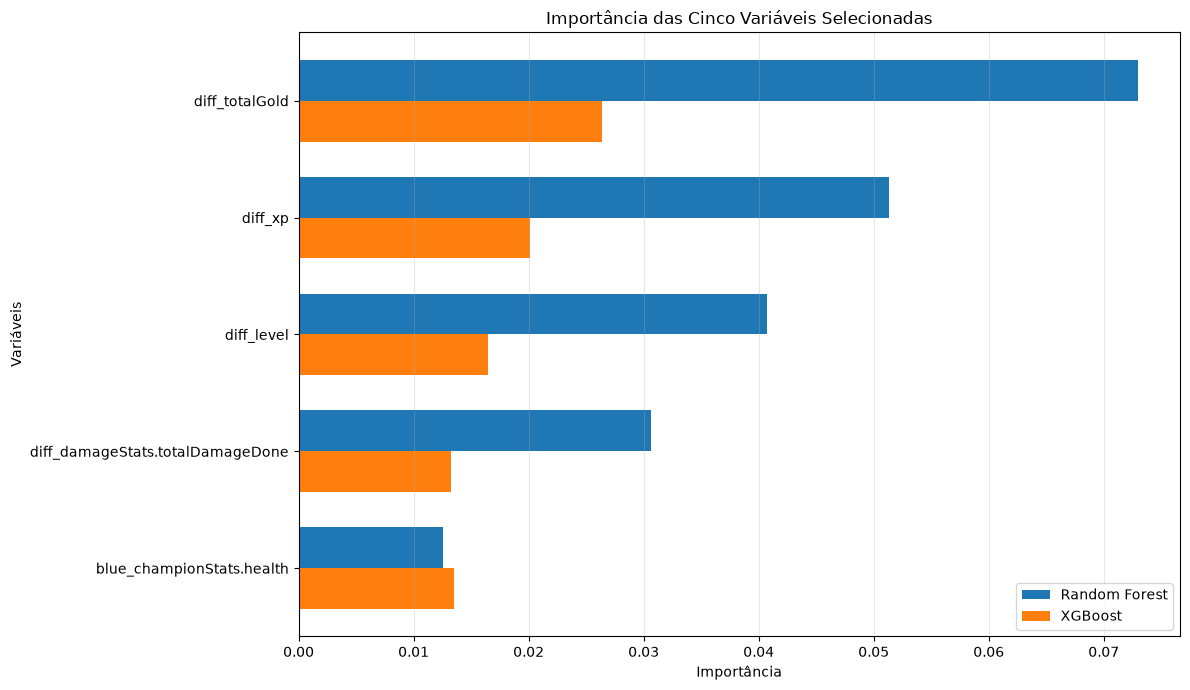

In [34]:
import matplotlib.pyplot as plt
import numpy as np

# Dados das cinco variáveis selecionadas
variaveis = cinco_variaveis.index.tolist()

importancia_rf = cinco_variaveis["Importância RF"].values
importancia_xgb = cinco_variaveis["Importância XGBoost"].values

# Posições das barras
y = np.arange(len(variaveis))
largura = 0.35

# Criação do gráfico
plt.figure(figsize=(12, 7))

plt.barh(
    y - largura / 2,
    importancia_rf,
    largura,
    label="Random Forest"
)

plt.barh(
    y + largura / 2,
    importancia_xgb,
    largura,
    label="XGBoost"
)

# Configurações visuais
plt.yticks(y, variaveis)
plt.xlabel("Importância")
plt.ylabel("Variáveis")
plt.title("Importância das Cinco Variáveis Selecionadas")

plt.legend()
plt.grid(axis="x", alpha=0.3)

# Exibe a variável mais importante no topo
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [35]:
print("=" * 70)
print("        RELATÓRIO - RANDOM FOREST E XGBOOST")
print("=" * 70)

print("\n1. PREPARAÇÃO DOS DADOS")
print(f"Total de partidas: {X.shape[0]}")
print(f"Período analisado: timesteps 0 a 20 (primeiros 20 minutos)")
print(f"Registros temporais por partida: {len(range(21))}")
print(f"Variáveis originais: {len(feature_columns)}")
print(f"Características utilizadas por partida: {X.shape[1]}")

print("\n2. DIVISÃO CRONOLÓGICA")
print(f"Treinamento: {len(X_train)} partidas ({len(X_train)/len(X)*100:.1f}%)")
print(f"Validação: {len(X_val)} partidas ({len(X_val)/len(X)*100:.1f}%)")
print(f"Teste: {len(X_test)} partidas ({len(X_test)/len(X)*100:.1f}%)")

print("\n3. CONFIGURAÇÃO DOS MODELOS")
print("Random Forest:")
print(f"  Número de árvores: {random_forest.n_estimators}")
print(f"  Max features: {random_forest.max_features}")

print("\nXGBoost:")
print(f"  Número de árvores: {xgboost_model.n_estimators}")
print(f"  Profundidade máxima: {xgboost_model.max_depth}")
print(f"  Taxa de aprendizado: {xgboost_model.learning_rate}")

print("\n4. RESULTADOS NO CONJUNTO DE TESTE")
print(f"{'Métrica':<25} {'Random Forest':>15} {'XGBoost':>15}")
print("-" * 57)
print(f"{'Accuracy':<25} {test_accuracy:>15.4f} {test_accuracy_xgb:>15.4f}")
print(f"{'F1-score (Macro)':<25} {test_f1:>15.4f} {test_f1_xgb:>15.4f}")
print(f"{'Balanced Accuracy':<25} {test_balanced_acc:>15.4f} {test_balanced_acc_xgb:>15.4f}")

print("\n5. CINCO VARIÁVEIS SELECIONADAS EM COMUM")
print(f"Limite utilizado nos rankings: Top {limite_top}")

for posicao, (variavel, linha) in enumerate(cinco_variaveis.iterrows(), start=1):
    print(
        f"{posicao}. {variavel} "
        f"(Ranking RF: {linha['Ranking RF']:.0f}; "
        f"Ranking XGBoost: {linha['Ranking XGBoost']:.0f})"
    )

print("\n6. CONCLUSÃO")
print(
    "Os modelos Random Forest e XGBoost foram utilizados para "
    "classificar o vencedor das partidas com base nos dados dos "
    "primeiros 20 minutos."
)
print(
    "A avaliação foi realizada utilizando uma divisão cronológica "
    "dos dados, e as importâncias das características foram analisadas "
    "para identificar variáveis relevantes para a classificação."
)

print("\n" + "=" * 70)

        RELATÓRIO - RANDOM FOREST E XGBOOST

1. PREPARAÇÃO DOS DADOS
Total de partidas: 10000
Período analisado: timesteps 0 a 20 (primeiros 20 minutos)
Registros temporais por partida: 21
Variáveis originais: 105
Características utilizadas por partida: 2205

2. DIVISÃO CRONOLÓGICA
Treinamento: 7000 partidas (70.0%)
Validação: 1500 partidas (15.0%)
Teste: 1500 partidas (15.0%)

3. CONFIGURAÇÃO DOS MODELOS
Random Forest:
  Número de árvores: 200
  Max features: sqrt

XGBoost:
  Número de árvores: 200
  Profundidade máxima: 6
  Taxa de aprendizado: 0.1

4. RESULTADOS NO CONJUNTO DE TESTE
Métrica                     Random Forest         XGBoost
---------------------------------------------------------
Accuracy                           0.7507          0.7547
F1-score (Macro)                   0.7493          0.7529
Balanced Accuracy                  0.7492          0.7525

5. CINCO VARIÁVEIS SELECIONADAS EM COMUM
Limite utilizado nos rankings: Top 21
1. diff_totalGold (Ranking RF: 1; Ran